In [101]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [102]:
from unncdb_dataset import Calculation, Database, Filters, ReflectionGrid

db = Database("dbname=unncdb_v2")
settings = dict(
    filters=Filters(r_max=0.1, reject_disorder=True),
    grid=ReflectionGrid.cube(4),
    calculation=Calculation(wavelength=0.71073, anomalous=True),
)

In [103]:
from sklearn.model_selection import train_test_split

data = db.build(n=1000, balance=True, seed=42, max_candidates=10000, **settings)
manifest = data.attrs["manifest"]

cell_columns = ["a", "b", "c", "alpha", "beta", "gamma"]
feature_columns = manifest["feature_columns"]
target_column = manifest["target_column"]

train = train_test_split(data, test_size=0.1, random_state=42)[0]
X_train = train[feature_columns]
y_train = train[target_column]

In [104]:
def find_overlaps(frame, reference, columns):
    reference_values = {column: reference[column].to_numpy() for column in columns}
    return frame[columns].isin(reference_values).any(axis=1)

In [105]:
previous_test = db.build(n=2000, balance=True, seed=31415, max_candidates=20000, **settings)

overlap_columns = ["family_id", "structure_hash", "cif_sha256"]
previous_test = previous_test.loc[~find_overlaps(previous_test, data, overlap_columns)]

exploratory_data = db.build(n=2000, balance=True, seed=2718, max_candidates=20000, **settings)

identity_columns = ["structure_id", *overlap_columns]

prior_identities = pd.concat(
    [data[identity_columns], previous_test[identity_columns], exploratory_data[identity_columns]],
    ignore_index=True,
)

In [106]:
candidates = db.build(n=1200, balance=False, seed=8675309, max_candidates=10000, **settings)

seen_before = find_overlaps(candidates, prior_identities, identity_columns)

test = candidates.loc[~seen_before].head(1000)

if len(test) < 1000:
    raise ValueError("после исключения пересечений осталось меньше 1 000 структур.")

In [107]:
X_test = test[feature_columns]
y_test = test[target_column]

count_table = pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()})
print(count_table.sort_index().rename_axis("Class").to_string())

       Train  Test
Class             
0        458   228
1        442   772


## Logistic Regression

In [108]:
from sklearn.linear_model import LogisticRegressionCV

logistic_model = LogisticRegressionCV(cv=5, max_iter=5000, random_state=42, scoring="accuracy")
logistic_model.fit(X_train, y_train);

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details

## SVM

In [109]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV


def make_svm_search(c_values, gamma_values):
    return GridSearchCV(
        make_pipeline(
            SimpleImputer(strategy="median", keep_empty_features=True),
            StandardScaler(),
            SVC(kernel="rbf"),
        ),
        {"svc__C": c_values, "svc__gamma": gamma_values},
        cv=5,
        scoring="balanced_accuracy",
        error_score="raise",
    )

In [ ]:
baseline_svm = make_svm_search([0.01, 0.1, 1, 10], ["scale", 0.01, 0.1])
baseline_svm.fit(X_train, y_train)
print(baseline_svm.best_params_)

{'svc__C': 1, 'svc__gamma': 'scale'}


In [111]:
def friedel_pair_indices(hkl):
    '''Возвращает индексы обоих отражений каждой пары'''
    
    positions = {tuple(index): i for i, index in enumerate(hkl)}
    pairs = []
    for i, (h, k, l) in enumerate(hkl):
        j = positions.get((-h, -k, -l))
        if j is not None and i < j:
            pairs.append((i, j))

    if not pairs:
        raise ValueError("Для признаков нужны пары hkl и −h−k−l.")
    return np.array(pairs).T

In [112]:
def friedel_pair_intensities(frame):
    '''Вычисляет сумму и абсолютную разность интенсивностей в каждой паре'''
    
    manifest = frame.attrs["manifest"]
    if manifest["calculation"]["quantity"] != "intensity":
        raise ValueError("Для признаков нужны интенсивности I(hkl).")

    left, right = friedel_pair_indices(manifest["hkl"])
    intensities = frame[manifest["reflection_columns"]].to_numpy(dtype=float)
    left_intensities = intensities[:, left]
    right_intensities = intensities[:, right]
    pair_sums = left_intensities + right_intensities
    pair_differences = np.abs(left_intensities - right_intensities)
    return pair_sums, pair_differences

In [113]:
def normalize_pair_sums(pair_sums):
    '''Делит суммы интенсивностей на среднюю сумму по структуре.'''
    
    mean_sum = np.nanmean(pair_sums, axis=1, keepdims=True)
    if np.any(~np.isfinite(mean_sum) | (mean_sum <= 0)):
        raise ValueError("У каждой структуры должны быть наблюдаемые пары с ненулевым сигналом.")
    return pair_sums / mean_sum

In [114]:
def pair_intensity_features(normalized_sums):
    '''Считает 11 статистик яркости пар для каждой структуры.'''
    deviation = np.nanmean(np.abs(normalized_sums - 1), axis=1)
    mean_roots = np.nanmean(np.sqrt(normalized_sums), axis=1)
    mean_squares = np.nanmean(normalized_sums ** 2, axis=1)

    quantile_levels = [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    quantiles = np.nanquantile(normalized_sums, quantile_levels, axis=1).T

    observed_counts = np.isfinite(normalized_sums).sum(axis=1)
    zero_fraction = (normalized_sums == 0).sum(axis=1) / observed_counts

    return np.column_stack([deviation, mean_roots, mean_squares, quantiles, zero_fraction])

In [115]:
def pair_difference_features(pair_sums, pair_differences, normalized_sums):
    '''Считает пять статистик различий внутри пар в логарифмическом масштабе.'''

    total_ratio = np.nansum(pair_differences, axis=1) / np.nansum(pair_sums, axis=1)

    squared_differences = np.nansum(pair_differences ** 2, axis=1)

    squared_sums = np.nansum(pair_sums ** 2, axis=1)

    rms_ratio = np.sqrt(squared_differences / squared_sums)

    strong_pairs = normalized_sums > 0.1

    relative_differences = np.full_like(pair_sums, np.nan)

    np.divide(pair_differences, pair_sums, out=relative_differences, where=strong_pairs)
    
    quantiles = np.nanquantile(relative_differences, [0.5, 0.9, 0.99], axis=1).T

    statistics = np.column_stack([total_ratio, rms_ratio, quantiles])
    return np.log10(np.maximum(statistics, 1e-12))

In [116]:
def friedel_features(frame):
    pair_sums, pair_differences = friedel_pair_intensities(frame)
    normalized_sums = normalize_pair_sums(pair_sums)

    intensity_features = pair_intensity_features(normalized_sums)
    difference_features = pair_difference_features(pair_sums, pair_differences, normalized_sums)
    return np.column_stack([frame[cell_columns], intensity_features, difference_features])

In [117]:
X_train_friedel = friedel_features(train)
X_test_friedel = friedel_features(test)

In [118]:
friedel_svm = make_svm_search([1, 10], ["scale", 0.1])
friedel_svm.fit(X_train_friedel, y_train)
print(friedel_svm.best_params_)

{'svc__C': 1, 'svc__gamma': 'scale'}


In [119]:
X_train_friedel

array([[ 34.115     ,   9.783     ,  19.635     , ..., -12.        ,
        -12.        , -12.        ],
       [ 11.327     ,  10.207     ,  14.452     , ..., -12.        ,
        -12.        , -12.        ],
       [  9.5266    ,   9.6896    ,  42.705     , ...,  -2.13268684,
         -1.34525532,  -0.96756079],
       ...,
       [ 12.35      ,  14.3025    ,  21.079     , ..., -12.        ,
        -12.        , -12.        ],
       [ 13.677     ,  34.017     ,  10.88      , ...,  -1.67299944,
         -1.04751066,  -0.68939073],
       [ 18.0187    ,  13.546     ,  18.092     , ..., -12.        ,
        -12.        , -12.        ]], shape=(900, 22))

## Compare

Все модели проверяются на одной тысяче структур. Класс 0 — нецентросимметричные, класс 1 — центросимметричные. В матрицах ошибок строки — истинные классы, столбцы — предсказанные.

In [120]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [121]:
def evaluate_model(model, inputs, labels):
    predictions = model.predict(inputs)
    scores = model.decision_function(inputs)
    report = classification_report(
        labels, predictions, labels=[0, 1], output_dict=True, zero_division=0,
    )
    metrics = {
        "accuracy": report["accuracy"],
        "balanced accuracy": report["macro avg"]["recall"],
        "macro F1": report["macro avg"]["f1-score"],
        "weighted F1": report["weighted avg"]["f1-score"],
        "ROC AUC": roc_auc_score(labels, scores),
    }
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    return metrics, matrix, report, scores

In [146]:
models = [
    #("Logistic Regression", logistic_model, X_test),
    ("SVM", baseline_svm, X_test),
    #("SVM with new features", friedel_svm, X_test_friedel),
]

results = []
matrices = {}
reports = {}
decision_scores = {}
for name, model, inputs in models:
    metrics, matrices[name], reports[name], decision_scores[name] = evaluate_model(
        model, inputs, y_test,
    )
    results.append({"Model": name, **metrics})

In [123]:
result_table = pd.DataFrame(results).set_index("Model")
print(result_table.to_string(formatters={
    "accuracy": "{:.1%}".format,
    "balanced accuracy": "{:.1%}".format,
    "macro F1": "{:.3f}".format,
    "weighted F1": "{:.3f}".format,
    "ROC AUC": "{:.4f}".format,
}))

                      accuracy balanced accuracy macro F1 weighted F1 ROC AUC
Model                                                                        
Logistic Regression      64.9%             67.8%    0.610       0.677  0.7367
SVM                      77.8%             77.4%    0.728       0.791  0.8418
SVM with new features    99.7%             99.8%    0.996       0.997  1.0000


In [124]:
for name, matrix in matrices.items():
    print(f"\n{name}")
    print(pd.DataFrame(
        matrix, index=["Class 0", "Class 1"], columns=["Pred 0", "Pred 1"],
    ).to_string())


Logistic Regression
         Pred 0  Pred 1
Class 0     167      61
Class 1     290     482

SVM
         Pred 0  Pred 1
Class 0     175      53
Class 1     169     603

SVM with new features
         Pred 0  Pred 1
Class 0     228       0
Class 1       3     769


### Confusion matrices


In [125]:
def plot_confusion_matrix(name, matrix):
    ratios = matrix / matrix.sum(axis=1, keepdims=True)
    annotations = [
        [f"{count}\n{ratio:.1%}" for count, ratio in zip(count_row, ratio_row)]
        for count_row, ratio_row in zip(matrix, ratios)
    ]

    fig, ax = plt.subplots(figsize=(5.1, 3.4), layout="constrained")
    sns.heatmap(ratios, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=1,
                xticklabels=[0, 1], yticklabels=[0, 1], ax=ax,
                cbar_kws={"format": "{x:.0%}"})
    ax.set(title=name, xlabel="Predicted class", ylabel="True class")
    ax.tick_params(axis="y", labelrotation=0)
    plt.show()

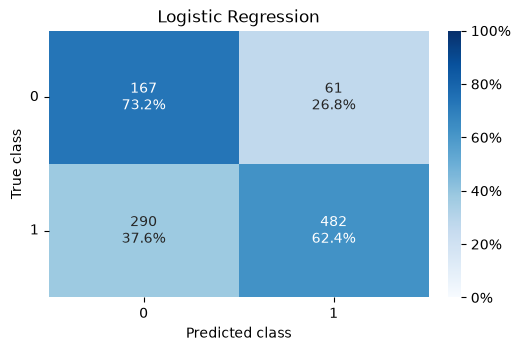

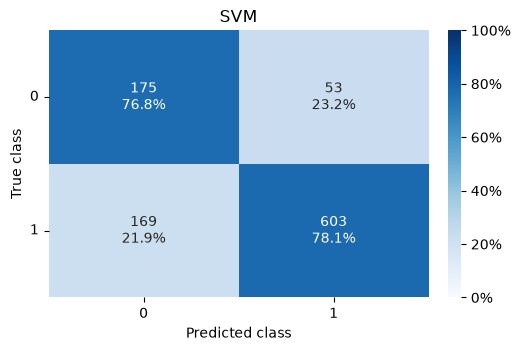

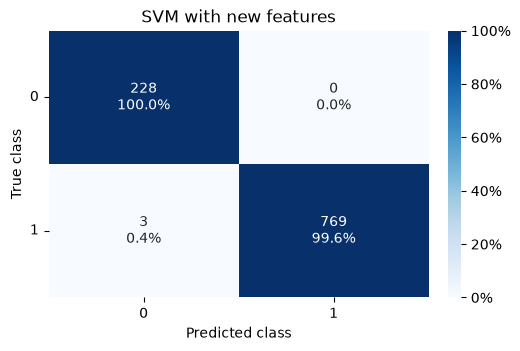

In [126]:
for name, matrix in matrices.items():
    plot_confusion_matrix(name, matrix)

### Classification reports

**Precision** — доля правильных прогнозов среди всех прогнозов данного класса. **Recall** — доля найденных объектов среди всех объектов этого класса. **F1** — гармоническое среднее precision и recall. В строках классов указано число объектов в тесте. **Macro avg** усредняет классы с равным весом, **Weighted avg** взвешивает их по числу тестовых объектов.

In [127]:
def plot_classification_report(name, report):
    rows = ["0", "1", "macro avg", "weighted avg"]
    metrics = ["precision", "recall", "f1-score"]
    values = pd.DataFrame(report).T.loc[rows, metrics]
    values.index = [
        f"Class 0 (n={report['0']['support']:.0f})",
        f"Class 1 (n={report['1']['support']:.0f})",
        "Macro avg", "Weighted avg",
    ]

    fig, ax = plt.subplots(figsize=(6.1, 3.2), layout="constrained")
    sns.heatmap(values, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
                linewidths=0.5, cbar_kws={"ticks": [0, 0.25, 0.5, 0.75, 1]}, ax=ax)
    ax.set_title(name)
    ax.tick_params(axis="y", labelrotation=0)
    plt.show()

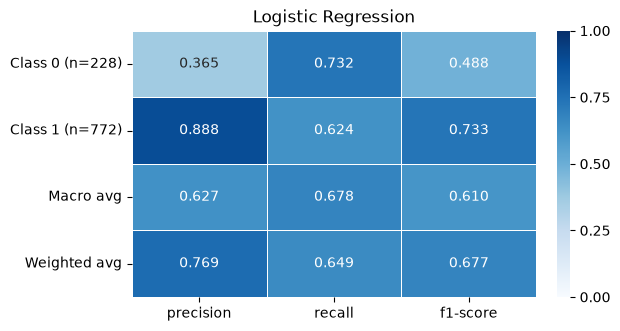

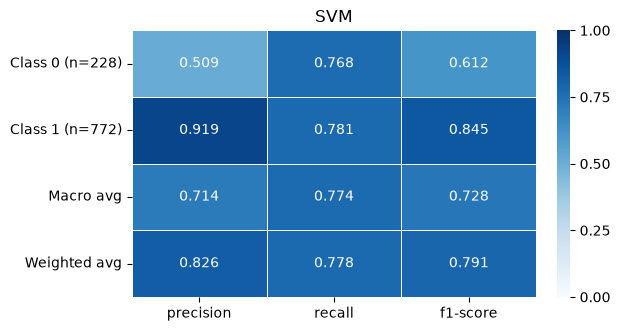

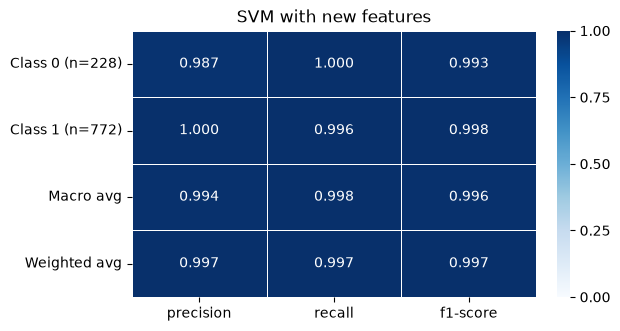

In [128]:
for name, report in reports.items():
    plot_classification_report(name, report)

In [129]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

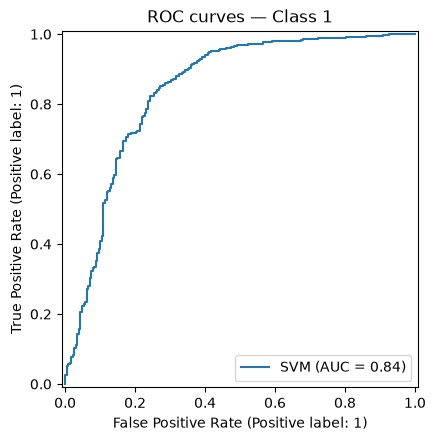

In [148]:
fig, ax = plt.subplots(figsize=(6.3, 4.3), layout="constrained")
for name, scores in decision_scores.items():
    RocCurveDisplay.from_predictions(y_test, scores, pos_label=1, name=name, ax=ax)

#ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set_title("ROC curves — Class 1")
ax.legend(loc="lower right")
plt.show()

In [131]:
def plot_precision_recall(ax, labels, scores_by_model, positive_class):
    average_precision = {}
    for name, scores in scores_by_model.items():
        class_scores = scores if positive_class == 1 else -scores
        curve = PrecisionRecallDisplay.from_predictions(
            labels, class_scores, pos_label=positive_class, name=name, ax=ax,
        )
        average_precision[name] = curve.average_precision

    prevalence = (labels == positive_class).mean()
    ax.axhline(prevalence, linestyle="--", color="gray", label=f"Class share = {prevalence:.1%}")
    ax.set_title(f"Precision–Recall — Class {positive_class}")
    ax.legend(loc="lower left")
    return average_precision

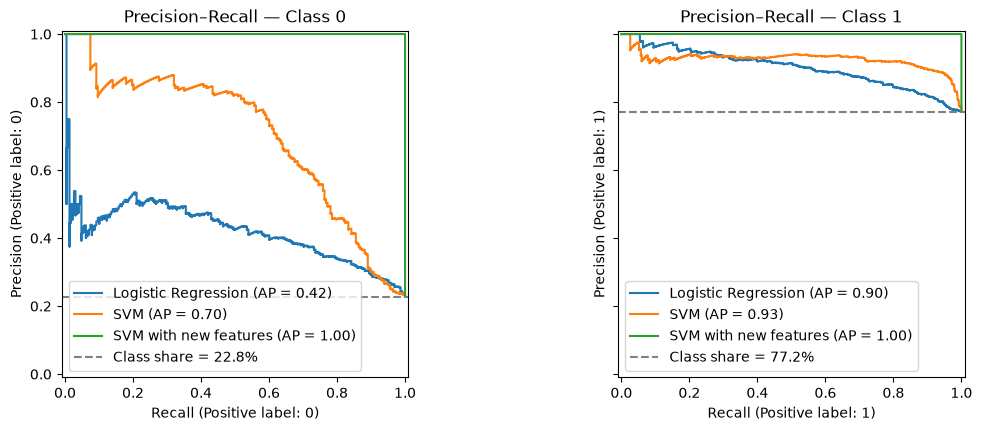

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(11.1, 4.2), sharey=True, layout="constrained")
pr_average_precision = {}
for positive_class, ax in enumerate(axes):
    pr_average_precision[positive_class] = plot_precision_recall(
        ax, y_test, decision_scores, positive_class,
    )
plt.show()

In [133]:
from itertools import product
from sklearn.metrics import balanced_accuracy_score, recall_score
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.model_selection import StratifiedKFold

In [134]:
def scaled_squared_distances(X_fit, X_other):
    fit_distances = euclidean_distances(X_fit, squared=True)
    nonzero = fit_distances[fit_distances > 0]
    scale = np.median(nonzero) if nonzero.size else 1.0
    other_distances = euclidean_distances(X_other, X_fit, squared=True)
    return fit_distances / scale, other_distances / scale

In [135]:
def intensity_distance_blocks(X_fit, X_other):
    transforms = {"raw": np.asarray, "sqrt": np.sqrt, "log": np.log1p}
    blocks = {"indexed": scaled_squared_distances(np.log1p(X_fit), np.log1p(X_other))}
    for name, transform in transforms.items():
        fit_sorted = np.sort(transform(X_fit), axis=1)
        other_sorted = np.sort(transform(X_other), axis=1)
        blocks[name] = scaled_squared_distances(fit_sorted, other_sorted)
    return blocks

In [136]:
def distribution_distance_blocks(X_fit, X_other):
    imputer = SimpleImputer(strategy="median", keep_empty_features=True).fit(X_fit)
    fit = imputer.transform(X_fit)
    other = imputer.transform(X_other)

    scaler = StandardScaler().fit(fit[:, :6])
    fit_cell = scaler.transform(fit[:, :6])
    other_cell = scaler.transform(other[:, :6])
    blocks = intensity_distance_blocks(fit[:, 6:], other[:, 6:])
    blocks["cell"] = scaled_squared_distances(fit_cell, other_cell)
    return blocks

In [137]:
def distribution_kernel(blocks, transform, gamma, cell_weight, indexed_weight):
    distribution_weight = 1 - cell_weight - indexed_weight
    return tuple(
        distribution_weight * np.exp(-gamma * blocks[transform][i])
        + cell_weight * np.exp(-blocks["cell"][i])
        + indexed_weight * np.exp(-blocks["indexed"][i])
        for i in range(2)
    )

In [138]:
distribution_weights = [(0, 0), (.1, 0), (.25, 0), (0, .1), (0, .25), (.15, .15)]
distribution_grid = list(product(["raw", "sqrt", "log"], [.1, .5, 2, 8], distribution_weights))
distribution_C_values = [.3, 1, 3, 10, 30]

In [139]:
def select_distribution_svm(X, y):
    scores = np.empty((len(distribution_grid), len(distribution_C_values), 5))
    for fold, (fit, validation) in enumerate(StratifiedKFold(n_splits=5).split(X, y)):
        blocks = distribution_distance_blocks(X[fit], X[validation])
        for i, (transform, gamma, weights) in enumerate(distribution_grid):
            fit_kernel, val_kernel = distribution_kernel(blocks, transform, gamma, *weights)
            for j, C in enumerate(distribution_C_values):
                model = SVC(kernel="precomputed", C=C).fit(fit_kernel, y[fit])
                scores[i, j, fold] = balanced_accuracy_score(y[validation], model.predict(val_kernel))

    mean_scores = scores.mean(axis=2)
    i, j = np.unravel_index(mean_scores.argmax(), mean_scores.shape)
    return distribution_grid[i], distribution_C_values[j], mean_scores[i, j]

In [140]:
distribution_params, distribution_C, distribution_cv_score = select_distribution_svm(
    X_train.to_numpy(), y_train.to_numpy(),
)
print(f"Kernel: {distribution_params}, C={distribution_C}")
print(f"CV balanced accuracy: {distribution_cv_score:.1%}")

Kernel: ('sqrt', 0.5, (0.15, 0.15)), C=10
CV balanced accuracy: 92.8%


In [141]:
prior_roc_candidates = db.build(
    n=1200, balance=False, seed=5294017, max_candidates=10000, **settings,
)
distribution_history = pd.concat(
    [prior_identities, candidates[identity_columns], prior_roc_candidates[identity_columns]],
    ignore_index=True,
)
prior_svm_candidates = db.build(
    n=1200, balance=False, seed=563091, max_candidates=10000, **settings,
)
prior_svm_test = prior_svm_candidates.loc[
    ~find_overlaps(prior_svm_candidates, distribution_history, identity_columns)
].head(1000)

In [142]:
distribution_history = pd.concat(
    [distribution_history, prior_svm_test[identity_columns]], ignore_index=True,
)
distribution_candidates = db.build(
    n=1200, balance=False, seed=613987, max_candidates=10000, **settings,
)
distribution_test = distribution_candidates.loc[
    ~find_overlaps(distribution_candidates, distribution_history, identity_columns)
].head(1000)
if len(distribution_test) != 1000:
    raise ValueError("После исключения совпадений осталось меньше 1 000 структур.")

In [143]:
X_distribution_test = distribution_test[feature_columns]
y_distribution_test = distribution_test[target_column]
transform, gamma, weights = distribution_params
blocks = distribution_distance_blocks(X_train.to_numpy(), X_distribution_test.to_numpy())
train_kernel, test_kernel = distribution_kernel(blocks, transform, gamma, *weights)
distribution_svm = SVC(kernel="precomputed", C=distribution_C)
distribution_svm.fit(train_kernel, y_train);

In [144]:
distribution_results = []
for name, model, inputs in [
    ("SVM", baseline_svm, X_distribution_test),
    ("SVM with distribution kernel", distribution_svm, test_kernel),
]:
    predictions = model.predict(inputs)
    recall = recall_score(y_distribution_test, predictions, labels=[0, 1], average=None)
    auc = roc_auc_score(y_distribution_test, model.decision_function(inputs))
    distribution_results.append([name, recall[0], recall[1], recall.mean(), auc])

print(pd.DataFrame(distribution_results, columns=[
    "Model", "Recall 0", "Recall 1", "Balanced accuracy", "ROC AUC",
]).set_index("Model").round(4).to_string())

                              Recall 0  Recall 1  Balanced accuracy  ROC AUC
Model                                                                       
SVM                             0.7512    0.7789             0.7650   0.8250
SVM with distribution kernel    0.9343    0.9327             0.9335   0.9779


In [145]:
matrix = confusion_matrix(y_distribution_test, distribution_svm.predict(test_kernel), labels=[0, 1])
print(pd.DataFrame(matrix, index=["Class 0", "Class 1"], columns=["Pred 0", "Pred 1"]).to_string())

         Pred 0  Pred 1
Class 0     199      14
Class 1      53     734
